In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import statistics
import data.data as puzzle_data
from solver.backtracking import backtrack
import validator as validator
import time
import experiments.benchmark as benchmark
import experiments.validation_experiment as validation_experiment
import importlib

importlib.reload(validation_experiment)

<module 'experiments.validation_experiment' from '/Users/stefani/PycharmProjects/meowdoku_project/experiments/validation_experiment.py'>

# 4. Basic Backtracking

## 4.1 Introduction to Backtracking

Backtracking is a general algorithmic technique used to solve problems that involve finding a configuration satisfying a set of constraints. It constructs a solution incrementally, making one decision at a time. Whenever a decision leads to a state in which no valid continuation is possible, the algorithm returns to an earlier decision and explores another possibility.

In the context of Meowdoku, the objective is to place exactly one cat in each coloured region while satisfying the row, column and diagonal restrictions. Since each region must contain exactly one cat, the algorithm can process the regions one at a time and select a candidate cell for each region.

The basic backtracking algorithm follows three main steps:

1. **Selection:** Select the next region according to a fixed order.
2. **Exploration:** Try each candidate cell in that region, provided that placing a cat there does not violate any existing constraint.
3. **Backtracking:** If no valid solution can be completed from the current configuration, remove the most recently placed cat and try another candidate.

This process continues until either a complete valid arrangement is found or all possible configurations have been explored.

The algorithm used in this project serves as a baseline for evaluating more advanced search strategies. It uses a fixed region-selection order and does not apply additional heuristics such as Minimum Remaining Values (MRV) or forward checking.

## 4.2 Mathematical Explanation

The Meowdoku puzzle can be represented as a Constraint Satisfaction Problem (CSP). Each coloured region represents a variable, and its possible values are the cells belonging to that region.

Let the set of regions be

$$
\mathcal{R}=\{R_1,R_2,\ldots,R_n\}.
$$

For each region $R_k$, define its domain $D_k$ as the set of cells belonging to that region:

$$
D_k=\{(i,j)\in B\mid (i,j)\in R_k\}.
$$

The algorithm attempts to assign one cell to every region. A complete assignment is therefore represented by

$$
C=\{c_1,c_2,\ldots,c_n\},
$$

where each selected cell satisfies

$$
c_k\in D_k,\qquad k=1,\ldots,n.
$$

The following conditions must hold:

**1. Row constraint**

No two selected cells may belong to the same row:

$$
\operatorname{row}(c_k)\neq
\operatorname{row}(c_l),
\qquad k\neq l.
$$

**2. Column constraint**

No two selected cells may belong to the same column:

$$
\operatorname{col}(c_k)\neq
\operatorname{col}(c_l),
\qquad k\neq l.
$$

**3. Diagonal constraint**

No two selected cells may be diagonally adjacent. For any two distinct selected cells $c_k=(i,j)$ and $c_l=(p,q)$, the following condition must hold:

$$
|i-p|\neq 1
\quad\text{or}\quad
|j-q|\neq 1.
$$

The row and column restrictions also prevent horizontal and vertical adjacency.

A partial assignment is considered valid if all constraints are satisfied by the cats placed so far. If a newly selected cell violates any constraint, that candidate is rejected immediately.

The backtracking procedure can be expressed recursively. Let $S_k$ represent a valid partial assignment containing cats in the first $k$ regions. The algorithm attempts to extend this assignment by selecting a cell from the next region:

$$
S_{k+1}=S_k\cup\{c_{k+1}\}.
$$

If no candidate cell can extend the current assignment without violating the constraints, the algorithm returns to the previous partial assignment and explores another candidate.

A complete solution is reached when all regions have been assigned:

$$
|S_n|=n.
$$

At this point, every region contains exactly one cat, and all row, column and diagonal constraints are satisfied.

## 4.3 Algorithm Design

The basic backtracking algorithm processes regions in a predetermined order. Within each region, candidate cells are considered in a fixed order: from top to bottom and from left to right. This ensures that the search procedure is deterministic and consistent across repeated experiments.

The algorithm begins with an empty assignment, except for any pre-placed cats that must remain fixed. For Puzzle 181, the pre-placed cat is located at F7, represented by the coordinate $(6,5)$ using Python's zero-based indexing.

For each region, the algorithm examines its candidate cells and checks whether placing a cat in a particular cell satisfies all constraints. If the placement is valid, it is temporarily added to the current assignment, and the algorithm proceeds to the next region.

If a later region cannot be assigned a valid cell, the algorithm returns to the previous decision and removes the corresponding tentative placement. It then tries another candidate in that region. This process continues until a complete valid solution is found or all possible arrangements have been explored.

The algorithm uses depth-first search, exploring one sequence of placements as far as possible before returning to an earlier decision. Pre-placed cats are treated as fixed assignments and are never removed during the search.

The basic algorithm serves as the reference implementation against which the more advanced search strategies are compared.

## 4.4 Python Implementation

The basic backtracking algorithm was implemented in Python using a recursive search procedure. The implementation was divided into smaller functions, each responsible for a specific part of the solving process. This modular structure makes the algorithm easier to understand, test and maintain.

The first function, `get_region_cells()`, identifies all cell coordinates belonging to a given region. Candidate cells are returned in a fixed order, from top to bottom and from left to right. This ensures that the algorithm follows a consistent search strategy.

The second function, `is_valid_placement()`, checks whether a cat can be placed in a selected cell without violating the row, column or diagonal constraints. A candidate is accepted only if no conflicting cat is already present on the board.

The main function, `backtrack()`, performs the recursive search. It processes regions in a predetermined order and examines their candidate cells one at a time. When a valid placement is found, the algorithm temporarily adds the cat to the solution matrix and proceeds to the next region. If the search reaches a state where no valid continuation is possible, the previous tentative placement is removed, and another candidate is examined.

I have tested the functions on puzzle 181, which has an already placed cat. The result is identical with the real-life solution.

In [18]:
board_size = puzzle_data.puzzle_181["board_size"]

solution = [
    [0 for _ in range(board_size)]
    for _ in range(board_size)
]

for row, col in puzzle_data.puzzle_181["fixed_cats"]:
    solution[row][col] = 1

In [19]:
regions = puzzle_data.puzzle_181["regions"]

region_ids = sorted({
    region_id
    for row in regions
    for region_id in row
})

In [20]:
result = backtrack(regions, region_ids, 0, solution)

for row in result:
    print(row)

[0, 0, 0, 0, 1, 0, 0, 0]
[1, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 1, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 1, 0]
[0, 0, 0, 1, 0, 0, 0, 0]
[0, 1, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 1, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 1]


## 4.5 Testing the Algorithm

The basic backtracking algorithm is tested using the ten puzzles included in the dataset. Testing is performed before evaluating computational performance to ensure that the implementation produces valid results.

For each puzzle, the algorithm receives the region matrix and any pre-placed cats as input. It then attempts to find a complete arrangement satisfying all game constraints.

The computed solution is evaluated using the independent validation functions developed earlier. These functions check:

- Board dimensions.
- Region connectivity and region count.
- Exactly one cat in each row.
- Exactly one cat in each column.
- Exactly one cat in each region.
- The diagonal non-touching restriction.

The computed solution is also compared with the manually recorded solution. This provides an additional way to identify discrepancies between the algorithm's output and the original dataset.

Puzzle 181 receives particular attention because it contains a pre-placed cat at F7. The implementation must preserve this position throughout execution.

A puzzle is considered successfully solved when the algorithm returns a complete solution that passes all required validation checks. The testing results will be presented after the algorithm has been executed on the complete dataset.

In [21]:
test_puzzle = puzzle_data.puzzle_181.copy()

test_puzzle["solution"] = result

print("Dimensions:", validator.validate_dimensions(test_puzzle))
print("Regions:", validator.validate_regions(test_puzzle))
print("Rows:", validator.validate_rows(test_puzzle))
print("Columns:", validator.validate_columns(test_puzzle))
print("Region constraints:", validator.validate_region_constraints(test_puzzle))
print("Diagonal constraints:", validator.validate_diagonal_constraints(test_puzzle))

Dimensions: True
Regions: True
Rows: True
Columns: True
Region constraints: True
Diagonal constraints: True


In [22]:
for row, col in puzzle_data.puzzle_181["fixed_cats"]:
    print(f"Fixed cat preserved: {result[row][col] == 1}")

Fixed cat preserved: True


In [23]:
print("Matches original solution:", result == puzzle_data.puzzle_181["solution"])

Matches original solution: True


The search terminates when every region has been assigned a cat. The algorithm then returns the completed solution. If no valid arrangement can be found, it returns failure.

Pre-placed cats are included in the initial solution matrix and treated as fixed assignments. For Puzzle 181, the cat at F7 is represented using the zero-based Python coordinate $(6,5)$. This position is preserved throughout the search.

The implementation was first tested on Puzzle 181. The computed solution matched the manually recorded solution exactly and passed all six validation checks established in Section 3. This provided an initial confirmation that the algorithm correctly applies the mathematical constraints of the puzzle.

## 4.6 Experimental Design and Performance Measurements

The purpose of the experiment is to investigate how different search strategies affect the computational efficiency of solving Meowdoku puzzles.

The basic backtracking algorithm serves as the baseline for comparison with the two subsequent approaches: backtracking with Minimum Remaining Values (MRV), and backtracking with MRV combined with forward checking.

To ensure a fair comparison, all algorithms will use the same puzzle dataset, constraints, initial conditions and solution requirements. Each algorithm will process the puzzles in the same experimental setting and stop when it finds its first complete solution.

Several performance metrics will be recorded:

**1. Recursive calls**

The total number of times the recursive search function is executed. This indicates how many search states the algorithm explores.

**2. Execution time**

The time required by the algorithm to find a complete solution, measured in seconds.

**3. Backtracks**

The number of times a tentative cat placement is removed because the current search path cannot produce a complete solution.

The greatest number of recursive levels reached during execution. This indicates how far the algorithm progresses through the sequence of regions.

Execution time is measured separately from the search-related counters because it can be affected by hardware, background processes and other implementation details. To reduce the influence of timing fluctuations, each puzzle will be solved multiple times, and the median execution time will be used for the main comparison.

The experiment will examine both individual puzzle results and overall performance across the dataset. The results will be presented using tables and visualisations to identify differences between the search strategies.

Particular attention will be given to whether the use of more advanced search strategies reduces the number of explored search states and whether this reduction also results in shorter execution times.

The conclusions will be based on the observed measurements rather than on the initial hypotheses alone.

In [24]:
puzzles = {
    name.replace("puzzle_", ""): value
    for name, value in vars(puzzle_data).items()
    if name.startswith("puzzle_") and isinstance(value, dict)
}

print("Number of puzzles:", len(puzzles))
print("Puzzle IDs:", list(puzzles.keys()))

all_results = {}

for puzzle_id, puzzle in puzzles.items():

    all_results[puzzle_id] = benchmark.benchmark_puzzle(
        puzzle,
        repetitions=5
    )

print("Benchmarking completed.")

Number of puzzles: 10
Puzzle IDs: ['165', '166', '170', '174', '177', '178', '179', '180', '181', '182']
Benchmarking completed.


In [25]:
summary = []

for puzzle_id, runs in all_results.items():

    summary.append({
        "Puzzle ID": puzzle_id,
        "Board Size": puzzles[puzzle_id]["board_size"],
        "Median Time (seconds)": statistics.median(
            run["execution_time"] for run in runs
        ),
        "Recursive Calls": statistics.median(
            run["recursive_calls"] for run in runs
        ),
        "Backtracks": statistics.median(
            run["backtracks"] for run in runs
        )
    })

results_table = pd.DataFrame(summary)

results_table

,Puzzle ID,Board Size,Median Time (seconds),Recursive Calls,Backtracks
0,165,10,0.019018,1143,1132
1,166,10,0.016837,1461,1450
2,170,10,0.024192,2603,2592
3,174,9,0.020511,2575,2565
4,177,9,0.137338,17694,17684
5,178,10,0.011291,1230,1219
6,179,10,0.000455,62,51
7,180,10,0.027845,2831,2820
8,181,8,0.000170,28,19
9,182,10,0.006547,427,416


### Testing Results

The basic backtracking algorithm was tested on all ten puzzles in the dataset. A complete solution was successfully found for every puzzle.

To verify the correctness of the computed solutions, each result was evaluated using six independent validation checks: board dimensions, region connectivity and count, row constraints, column constraints, region constraints and diagonal non-touching constraints.

All ten computed solutions passed every validation check. The algorithm also correctly preserved the pre-placed cat in Puzzle 181.

These results confirm that the implementation correctly applies the mathematical rules of Meowdoku across the selected dataset. The successful validation establishes a reliable baseline for the performance comparison with the more advanced search strategies introduced in the following sections.

In [27]:
validation_results = validation_experiment.validate_all_puzzles(puzzles)

validation_table = pd.DataFrame(validation_results)

validation_table

,Puzzle ID,Solution found,All checks passed
0,165,True,True
1,166,True,True
2,170,True,True
3,174,True,True
4,177,True,True
5,178,True,True
6,179,True,True
7,180,True,True
8,181,True,True
9,182,True,True


## 4.7 Results and Discussion

The basic backtracking algorithm was evaluated using all ten puzzles in the dataset. Each puzzle was solved five times, and the median execution time was used to reduce the influence of timing fluctuations.

### Analysis of Recursive Calls and Backtracks

The following chart shows substantial variation in the number of recursive calls. Puzzle 177 required the most search operations, with 17,694 calls, whereas Puzzle 181 required only 28. This illustrates how strongly the search effort depends on the structure and constraints of an individual puzzle.

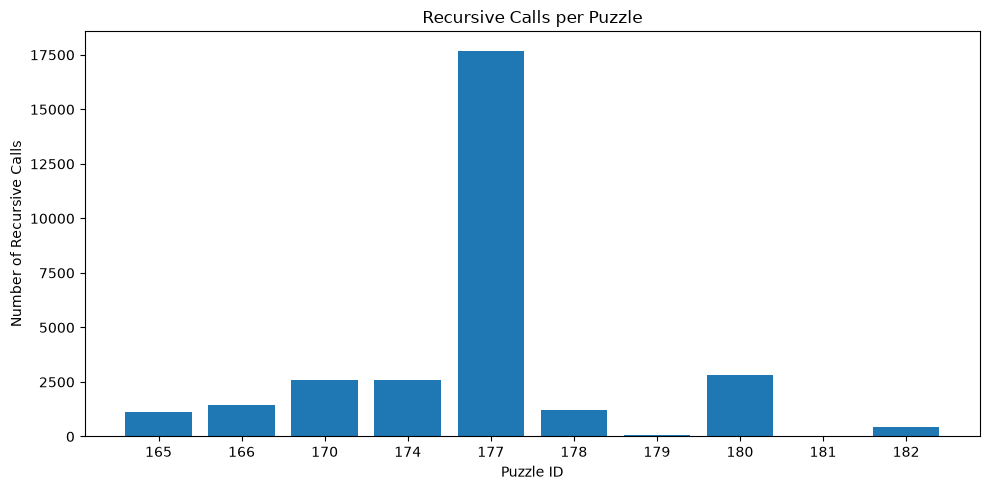

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_table["Puzzle ID"].astype(str),
    results_table["Recursive Calls"]
)

plt.title("Recursive Calls per Puzzle")
plt.xlabel("Puzzle ID")
plt.ylabel("Number of Recursive Calls")

plt.tight_layout()
plt.show()

### Analysis of Execution Time

Execution time also varied across the dataset. Puzzle 177 had the longest median execution time at 0.134347 seconds, while Puzzle 181 had the shortest at 0.000133 seconds.

The results show a relationship between the amount of search and execution time: puzzles requiring more recursive calls generally took longer to solve. However, execution time is also influenced by the computational work performed during each call.

Board size alone does not explain the differences in performance. For example, Puzzle 177 has a 9 × 9 board but required substantially more search than several 10 × 10 puzzles. Therefore, the structure of the regions and the interaction between constraints appear to be important factors affecting search complexity.

The following chart presents the median execution time for each puzzle across five runs. Puzzle 177 had the longest median execution time, while Puzzle 181 had the shortest. This broadly corresponds to the differences observed in recursive calls.


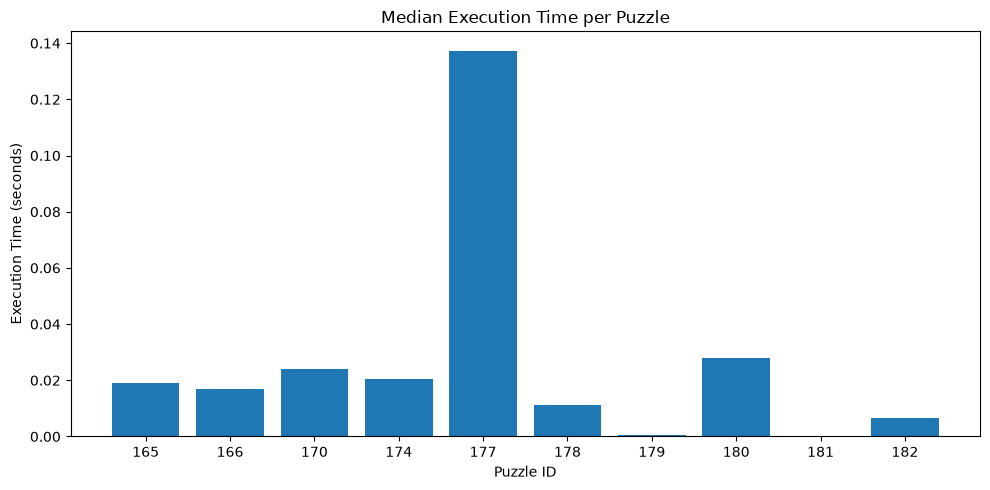

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_table["Puzzle ID"].astype(str),
    results_table["Median Time (seconds)"]
)

plt.title("Median Execution Time per Puzzle")
plt.xlabel("Puzzle ID")
plt.ylabel("Execution Time (seconds)")

plt.tight_layout()
plt.show()

### Discussion

The experiment demonstrates that basic backtracking can solve all ten puzzles correctly, but its computational effort varies significantly depending on the puzzle.

Because the algorithm processes regions in a fixed order, it may explore many candidate placements before discovering that an earlier decision prevents a complete solution. This limitation provides motivation for investigating more advanced search strategies.

In particular, selecting the most constrained region first may help reduce unnecessary exploration. This possibility will be examined in the next section through the Minimum Remaining Values heuristic.

## 4.8 Interim Conclusion

The basic backtracking algorithm successfully solved all ten puzzles in the dataset, and every computed solution passed the six independent validation checks.

The performance measurements revealed substantial differences in computational effort between puzzles. While some puzzles required very few recursive calls, others required considerably more exploration and backtracking.

These results establish basic backtracking as a functional baseline for the comparison of search strategies. However, the fixed region-order strategy does not account for how constrained each region is during the search.

The next section introduces the Minimum Remaining Values (MRV) heuristic, which selects the unassigned region with the smallest number of available candidate cells. The objective is to determine whether this strategy can reduce the search effort and improve computational efficiency.